# La transformacion composicional, paso a paso

## De que va esta libreta

Los datos de microbioma tienen una peculiaridad que, si se ignora, hace que los analisis
den resultados equivocados: **solo informan de proporciones, no de cantidades**. Aqui
vamos a ver por que eso es un problema y como se arregla, con una tabla de ejemplo que
generamos nosotros.

Son cuatro pasos:

1. **Amalgamar** los taxones raros
2. **Recerrar** la composicion
3. **Sustituir los ceros**
4. **Transformar con CLR**

## Como seguirla

Cada celda hace **una sola cosa** y va precedida de una explicacion. Las figuras estan en
un archivo aparte (`course_plots.py`), asi que en la libreta solo veras la linea que las
llama: el codigo de dibujar no aporta nada al tema.

Lo unico que hace falta es saber leer un `DataFrame` de pandas.

## Curso de Invierno — Microbioma de la rizósfera
### Instructor: Rafael Pérez-Estrada

⏱ **Duración estimada: ~50 min** (parte 1 de 3 del capítulo *Transformación composicional*)

**Cómo usar este notebook:** todas las celdas ya vienen escritas: ejecútalas en orden, siguiendo al instructor. Empieza por la celda **🔧 Setup**, que prepara el entorno igual en Google Colab y en tu computadora.  
Si te atrasas, ejecuta todas las celdas hasta donde vamos (en Colab: *Entorno de ejecución → Ejecutar anteriores*).

---

## 🔧 Setup (~2 min)

Prepara el código de apoyo del capítulo (las funciones de la cadena composicional y de las figuras). Esta libreta genera sus propios datos, así que no descarga nada más.

In [1]:
# Detección de entorno (VSCode local vs Google Colab) y preparación del código de apoyo
import os, sys, shutil, zipfile, urllib.request
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
LESSON = 'composicional'
NECESITA_DATOS = False   # esta libreta genera sus propios datos

# Archivos del repositorio (rama main)
RAMA = 'main'
REPO_URL = f'https://github.com/MicroAgroBiome/Curso_Invierno_2026/raw/{RAMA}/'
MODULOS = ['__init__', 'compositional', 'course_plots', 'simulation', 'batch']

if IN_COLAB:
    BASE = Path('/content')
else:
    # Local: sube hasta encontrar la carpeta datos/ (repo clonado); si no existe, usa la carpeta actual
    BASE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'datos').is_dir()), Path.cwd())

DATA_PATH = BASE / 'datos'
MODULE_PATH = BASE / 'src' / 'microagro_coda'
RESULTS_PATH = BASE / 'resultados' / LESSON

# Código de apoyo: en el repo ya está en src/; en Colab (o con el notebook suelto) se descarga
if not (MODULE_PATH / 'compositional.py').exists():
    MODULE_PATH.mkdir(parents=True, exist_ok=True)
    print("Descargando el código de apoyo...")
    for modulo in MODULOS:
        urllib.request.urlretrieve(f'{REPO_URL}src/microagro_coda/{modulo}.py', MODULE_PATH / f'{modulo}.py')
sys.path.insert(0, str(BASE / 'src'))

# Carpeta de trabajo: aquí quedan los resultados y, si hacen falta, los datos
PROCESSED_PATH = RESULTS_PATH / 'data' / 'processed'
PROCESSED_PATH.mkdir(parents=True, exist_ok=True)


def traer(nombre):
    """Ruta local de datos/<nombre>: usa la del repo o la descarga."""
    ruta = DATA_PATH / nombre
    if not ruta.exists():
        DATA_PATH.mkdir(parents=True, exist_ok=True)
        print(f"Descargando {nombre}...")
        urllib.request.urlretrieve(f'{REPO_URL}datos/{nombre}', ruta)
    return ruta


if NECESITA_DATOS:
    if not (PROCESSED_PATH / 'genus-counts-matrix.csv').exists():
        with zipfile.ZipFile(traer('composicional.zip')) as zf:
            for miembro in zf.namelist():
                if not miembro.endswith('/'):
                    (PROCESSED_PATH / Path(miembro).name).write_bytes(zf.read(miembro))
    shutil.copy(traer('subset_proyecto.zip'), RESULTS_PATH / 'data' / 'subset_proyecto.zip')

# El resto del notebook trabaja desde la carpeta de resultados
os.chdir(RESULTS_PATH)

print(f"Entorno: {'Google Colab' if IN_COLAB else 'Local (VSCode)'}")
print(f"Carpeta de trabajo: {os.path.relpath(RESULTS_PATH, BASE)}")

Entorno: Local (VSCode)
Carpeta de trabajo: resultados\composicional


## 1. Preparacion

Primero decimos donde esta el codigo del proyecto.

In [2]:
from pathlib import Path
import sys

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

Ahora las herramientas que vamos a usar.

In [3]:
import numpy as np
import pandas as pd

from microagro_coda import compositional as comp
from microagro_coda import course_plots as figuras
from microagro_coda import simulation as sim

figuras.preparar_libreta()

Y dos decisiones que tomamos de entrada. Volveremos sobre el umbral mas adelante.

In [4]:
UMBRAL_DE_PREVALENCIA = 0.70   # un taxon se conserva si aparece en al menos el 70 % de las muestras
SEMILLA = 42                   # para que los datos salgan iguales cada vez

## 2. Los datos

Generamos una tabla sintetica con la forma de un estudio de microbioma real. La
generamos nosotros para saber exactamente que hay dentro.

In [5]:
datos = sim.simulate_microbiome(sim.SimulationConfig(random_state=SEMILLA))

conteos = datos.counts
etiquetas = datos.labels

`conteos` es la tabla principal: **una fila por muestra y una columna por taxon**. Cada
valor es cuantas lecturas de secuenciacion cayeron en ese taxon.

In [6]:
conteos.shape

(900, 500)

In [7]:
conteos.iloc[:5, :6]

,Taxon-000,Taxon-001,Taxon-002,Taxon-003,Taxon-004,Taxon-005
sample,,,,,,
S0000,100,12397,11218,51723,483,20026
S0001,128203,31374,2665,14084,1011,1470
S0002,298,113888,148944,1475,451414,619
S0003,147,6356,21479,2003,2827,5105
S0004,592,66883,12585,7935,2082,12567


Y `etiquetas` dice a que grupo pertenece cada muestra. Son tres grupos del mismo tamano.

In [8]:
etiquetas.value_counts()

Clase A    300
Clase B    300
Clase C    300
Name: label, dtype: int64

## 3. El primer problema: cada muestra se secuencio distinto

Sumamos las lecturas de cada muestra. Eso es su **profundidad de secuenciacion**.

In [9]:
lecturas_por_muestra = conteos.sum(axis=1)
lecturas_por_muestra.head()

sample
S0000    314337
S0001    291719
S0002    902708
S0003    167990
S0004    188384
dtype: int64

Veamos cuanto varian.

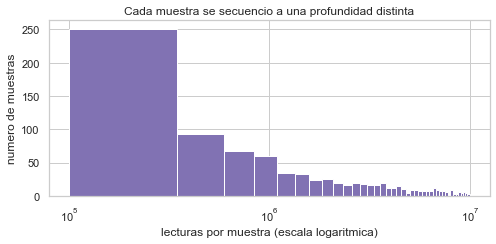

In [10]:
#| label: fig-l3-profundidad
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Lecturas por muestra en los datos simulados: la profundidad varía cien veces entre muestras."
figura = figuras.profundidad_por_muestra(lecturas_por_muestra)

La muestra con mas lecturas tiene **cien veces** mas que la que menos. Y eso no lo decide
la biologia: lo decide cuanta capacidad del secuenciador le toco a cada muestra.

Consecuencia practica: si un taxon tiene 5,000 lecturas en una muestra y 500 en otra, eso
**no significa** que sea diez veces mas abundante. Puede ser simplemente que la primera
muestra se secuencio mas a fondo.

In [11]:
#| label: l3-rango-profundidad
lecturas_por_muestra.max() / lecturas_por_muestra.min()

99.75240701530103

## 4. La solucion: cerrar la tabla

Dividimos cada fila entre su propio total. A esta operacion se le llama **cierre**:

$$x_{ij} = \frac{c_{ij}}{\sum_{l} c_{il}}$$

donde $c_{ij}$ son las lecturas del taxon $j$ en la muestra $i$. El resultado ya no son
lecturas sino **fracciones de la muestra**.

In [12]:
relativa = conteos.div(lecturas_por_muestra, axis=0)
relativa.iloc[:3, :5]

,Taxon-000,Taxon-001,Taxon-002,Taxon-003,Taxon-004
sample,,,,,
S0000,0.000318,0.039439,0.035688,0.164546,0.001537
S0001,0.439474,0.107549,0.009136,0.048279,0.003466
S0002,0.000330,0.126163,0.164997,0.001634,0.500066


Comprobemos que cada fila suma 1.

In [13]:
relativa.sum(axis=1).head()

sample
S0000    1.0
S0001    1.0
S0002    1.0
S0003    1.0
S0004    1.0
dtype: float64

Asi se ven dos muestras antes y despues de cerrar. A la izquierda parecen muy distintas;
a la derecha vemos que en realidad se parecen bastante.

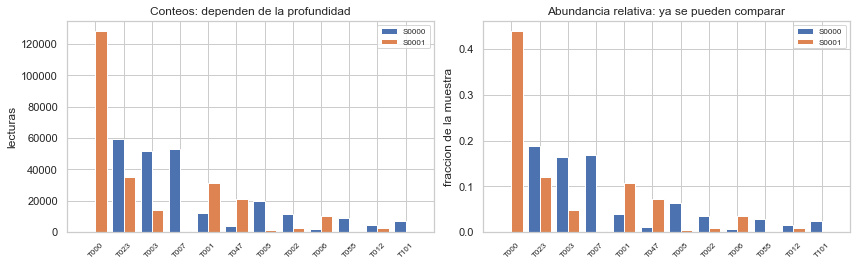

In [14]:
#| label: fig-l3-dos-muestras
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Dos muestras antes (conteos) y después (fracciones) de cerrar la tabla."
figura = figuras.dos_muestras_lado_a_lado(
    conteos, relativa, muestra_a="S0000", muestra_b="S0001"
)

### Lo que acabamos de ganar y lo que hemos perdido

Hemos ganado poder comparar muestras. Pero hemos perdido algo: ahora **las columnas estan
atadas entre si**. Como cada fila suma 1, si un taxon sube, los demas tienen que bajar
aunque no les haya pasado nada.

Esto es lo que hace a estos datos **composicionales**, y es la razon de todo lo que sigue.

## 5. El segundo problema: los ceros

Contemos que fraccion de la tabla son ceros.

In [15]:
#| label: l3-fraccion-ceros
(conteos == 0).to_numpy().mean()

0.35771555555555556

Mas de un tercio. Y la mayoria no son ausencias reales: son taxones raros a los que
simplemente no les toco ninguna lectura.

El problema es que el paso final toma **logaritmos**, y el logaritmo de cero no existe.
Asi que habra que sustituirlos. Cuantos menos ceros lleguemos a tener, menos tendremos que
inventar.

Veamos de donde vienen.

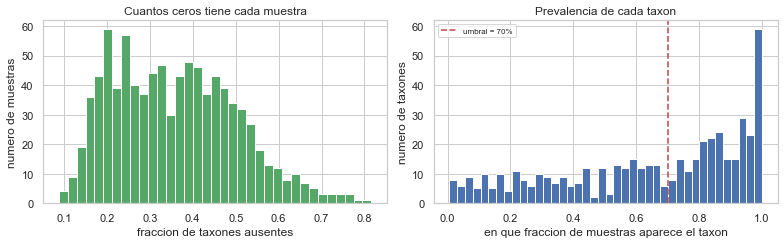

In [16]:
#| label: fig-l3-ceros-prevalencia
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "De dónde vienen los ceros: muchos taxones aparecen en muy pocas muestras."
figura = figuras.ceros_y_prevalencia(conteos, UMBRAL_DE_PREVALENCIA)

El panel de la derecha es la clave: muchos taxones aparecen en muy pocas muestras. Esos
son los que aportan casi todos los ceros.

## 6. Paso 1 de 4: amalgamar los taxones raros

**Amalgamar** es sumar varias partes en una sola. Tomamos todos los taxones que aparecen
en menos del 70 % de las muestras y los juntamos en una columna llamada `other-genera`:

$$x_{i,\text{otros}} = \sum_{j \in \mathcal{F}} x_{ij}$$

donde $\mathcal{F}$ es el conjunto de taxones poco prevalentes. Perdemos el detalle de
esos taxones, pero nos quitamos la mayor parte de los ceros.

Primero miramos cuantos son.

In [17]:
prevalencia = (relativa > 0).mean(axis=0)
raros = prevalencia[prevalencia < UMBRAL_DE_PREVALENCIA]
len(raros)

242

Ahora los agrupamos.

In [18]:
#| label: l3-amalgamar
amalgamada = comp.amalgamate_rare_genera(relativa, min_prevalence=UMBRAL_DE_PREVALENCIA)
amalgamada.shape

(900, 259)

Pasamos de 500 columnas a 259: las 258 que se quedan mas la columna `other-genera`.
Veamos cuantos ceros nos hemos quitado.

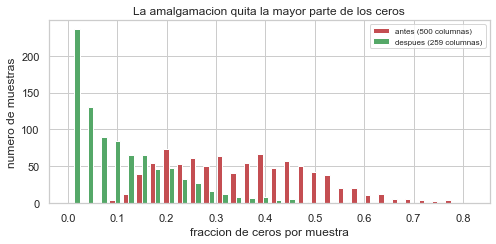

In [19]:
#| label: fig-l3-amalgamar
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Fracción de ceros antes y después de amalgamar los taxones raros en `other-genera`."
figura = figuras.antes_y_despues_de_amalgamar(relativa, amalgamada)

In [20]:
(amalgamada == 0).to_numpy().mean()

0.11272415272415272

De un 36 % de ceros a un 11 %.

## 7. Paso 2 de 4: recerrar

Al sumar y quitar columnas, las filas pueden dejar de sumar exactamente 1. Devolvemos lo
que falte a la columna `other-genera`:

$$x_{i,\text{otros}} \;\leftarrow\; x_{i,\text{otros}} + \Big(1 - \sum_j x_{ij}\Big)$$

Fijate en que **todo lo que falta va a una sola columna**, no se reparte entre todas. Es
una decision deliberada: lo que falta es masa que no sabemos de quien es, y es mas honesto
acumularla con el resto de lo desconocido.

In [21]:
#| label: l3-recerrar
recerrada = comp.reclose_modified(amalgamada, total=1.0)
recerrada.sum(axis=1).head()

sample
S0000    1.0
S0001    1.0
S0002    1.0
S0003    1.0
S0004    1.0
dtype: float64

## 8. Paso 3 de 4: sustituir los ceros

Ahora si hay que quitar los ceros, y hay que hacerlo **sin cambiar el total de la fila**.

La receta tiene dos partes. Primero elegimos el valor con el que rellenar: el **menor
valor positivo de toda la tabla**. No es un numero arbitrario, es el valor mas pequeno que
el experimento fue capaz de medir.

$$c = \min\{\, x_{ij} : x_{ij} > 0 \,\}$$

In [22]:
#| label: l3-pseudoconteo
valores = recerrada.to_numpy()
c = valores[valores > 0].min()
c

1.0012405370253745e-07

Segundo: si rellenamos los ceros, la fila sumaria mas de 1. Asi que a cada valor que **ya
era positivo** le restamos un poquito. Para la muestra $i$, con $n_i$ ceros y $p_i$ valores
positivos:

$$\delta_i = \frac{n_i \cdot c}{p_i}$$

La cuenta cuadra: anadimos $n_i$ veces $c$ y quitamos $p_i$ veces $\delta_i$, y

$$n_i \cdot c - p_i \cdot \frac{n_i \cdot c}{p_i} = 0$$

Calculemos $\delta_i$ para ver su tamano.

In [23]:
#| label: l3-delta
ceros_por_muestra = (recerrada == 0).sum(axis=1)
positivos_por_muestra = (recerrada > 0).sum(axis=1)

delta = ceros_por_muestra * c / positivos_por_muestra
delta.describe()

count    9.000000e+02
mean     1.503273e-08
std      1.965060e-08
min      0.000000e+00
25%      2.781224e-09
50%      8.834475e-09
75%      1.993210e-08
max      1.912482e-07
dtype: float64

Son cantidades minusculas. Apliquemos la receta.

In [24]:
sin_ceros = comp.replace_zeros_preserving_total(recerrada, variant="escrito")

Dos comprobaciones: ya no hay ceros, y las filas siguen sumando 1.

In [25]:
(sin_ceros > 0).to_numpy().all()

True

In [26]:
sin_ceros.sum(axis=1).head()

sample
S0000    1.0
S0001    1.0
S0002    1.0
S0003    1.0
S0004    1.0
dtype: float64

Asi se ve el cambio. La barra roja marca el pseudoconteo $c$: todos los ceros se apilan
justo ahi.

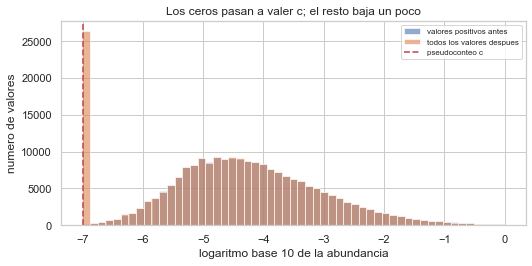

In [27]:
#| label: fig-l3-ceros
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Distribución de los valores antes y después de sustituir los ceros; la barra roja marca el pseudoconteo $c$."
figura = figuras.efecto_del_tratamiento_de_ceros(recerrada, sin_ceros, c)

### Una advertencia

Si una muestra tuviera **muchisimos** ceros, $n_i / p_i$ seria grande, $\delta_i$ tambien,
y podria dejar en negativo a los valores positivos mas pequenos. Entonces la receta no
funciona.

Por eso la amalgamacion va **antes**: quitando ceros primero, nos aseguramos de que el
descuento sea pequeno.

## 9. Paso 4 de 4: la transformacion CLR

Ya tenemos una tabla sin ceros. El ultimo paso es el que de verdad arregla el problema del
cierre.

CLR quiere decir *centered log-ratio*, log-razon centrada. Para cada muestra se calcula su
**media geometrica**, que es como una "media multiplicativa":

$$g(x_i) = \Big(\prod_{j} x_{ij}\Big)^{1/D}$$

y despues se divide cada valor entre ella y se toma logaritmo:

$$\mathrm{clr}(x_i)_j = \log \frac{x_{ij}}{g(x_i)}$$

En la practica esto es: tomar el logaritmo de toda la fila y restarle su media.

In [28]:
#| label: l3-clr
clr = comp.clr_transform(sin_ceros)
clr.iloc[:3, :5].round(3)

,Taxon-000,Taxon-001,Taxon-002,Taxon-003,Taxon-004
sample,,,,,
S0000,1.295,6.115,6.015,7.543,2.869
S0001,9.787,8.380,5.914,7.579,4.945
S0002,2.710,8.656,8.925,4.310,10.034


Los valores ya no son fracciones entre 0 y 1: son positivos o negativos segun el taxon
este por encima o por debajo de la media de su muestra.

Una propiedad que sale de la formula: **cada fila suma cero**.

In [29]:
clr.sum(axis=1).head().round(10)

sample
S0000   -0.0
S0001   -0.0
S0002   -0.0
S0003   -0.0
S0004   -0.0
dtype: float64

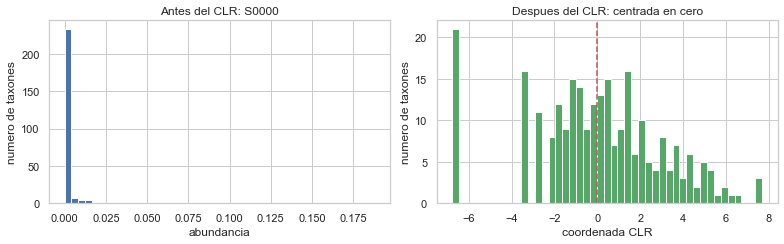

In [30]:
#| label: fig-l3-clr
#| code-fold: true
#| code-summary: "Ver el código de la gráfica"
#| fig-cap: "Una muestra antes y después de la transformación CLR."
figura = figuras.antes_y_despues_del_clr(sin_ceros, clr, muestra="S0000")

## 10. Por que el CLR arregla el problema

La propiedad importante es esta: **el CLR no cambia si multiplicas toda la fila por
cualquier numero**.

$$\mathrm{clr}(\lambda \cdot x_i) = \mathrm{clr}(x_i) \qquad \text{para cualquier } \lambda > 0$$

Es decir: da igual si partes de lecturas, de fracciones o de porcentajes. Y da igual si una
muestra se secuencio diez veces mas a fondo que otra.

Vamos a comprobarlo. Multiplicamos cada muestra por un numero distinto al azar.

In [31]:
#| label: l3-reescalar
generador = np.random.default_rng(SEMILLA)
factores = pd.Series(generador.uniform(0.01, 100, len(sin_ceros)), index=sin_ceros.index)

reescalada = sin_ceros.mul(factores, axis=0)
factores.head().round(2)

sample
S0000    77.40
S0001    43.89
S0002    85.86
S0003    69.74
S0004     9.43
dtype: float64

Las filas de `reescalada` ya no suman 1, suman cualquier cosa. Calculemos su CLR y
comparemoslo con el original.

In [32]:
#| label: l3-invariancia
clr_reescalada = comp.clr_transform(reescalada)

diferencia_maxima = (clr - clr_reescalada).abs().to_numpy().max()
diferencia_maxima

6.927791673660977e-14

Practicamente cero: la diferencia es del orden de $10^{-14}$, que es el error de redondeo
de la computadora. **Son la misma matriz.**

Eso es exactamente lo que queriamos: una representacion que no dependa de cuanto se
secuencio cada muestra.

## 11. Resumen

Esto es lo que le paso a la tabla en cada paso.

In [33]:
etapas = {
    "conteos": conteos,
    "cerrada": relativa,
    "amalgamada": amalgamada,
    "recerrada": recerrada,
    "sin ceros": sin_ceros,
    "CLR": clr,
}

Y recorremos las etapas midiendo tres cosas en cada una.

In [34]:
#| label: tbl-l3-resumen
#| tbl-cap: "Qué le pasa a la tabla en cada etapa de la cadena composicional."
columnas = {}
ceros = {}
minimos = {}

for nombre, tabla in etapas.items():
    columnas[nombre] = tabla.shape[1]
    ceros[nombre] = round((tabla == 0).to_numpy().mean(), 3)
    minimos[nombre] = "%.2e" % tabla.to_numpy().min()

resumen = pd.DataFrame({"columnas": columnas, "ceros": ceros, "valor minimo": minimos})
resumen

,columnas,ceros,valor minimo
conteos,500,0.358,0.00e+00
cerrada,500,0.358,0.00e+00
amalgamada,259,0.113,0.00e+00
recerrada,259,0.113,0.00e+00
sin ceros,259,0.000,9.93e-08
CLR,259,0.000,-7.57e+00


Y lo que hay que retener de cada paso:

| paso | que hace | para que |
|---|---|---|
| **Cerrar** | divide cada fila entre su total | poder comparar muestras secuenciadas a distinta profundidad |
| **1. Amalgamar** | junta los taxones raros en una columna | reducir los ceros que habra que inventar |
| **2. Recerrar** | devuelve el faltante a `other-genera` | que cada fila vuelva a sumar 1 |
| **3. Sustituir ceros** | rellena con $c$ y descuenta $\delta_i$ | poder tomar logaritmos sin cambiar el total |
| **4. CLR** | logaritmo menos la media de la fila | quitar el efecto de la profundidad y poder usar metodos normales |

En la siguiente libreta usamos esta tabla transformada para clasificar, y comparamos que
pasa si nos saltamos la correccion.

## Guardar el resultado

La siguiente libreta vuelve a generar los mismos datos, asi que esto es opcional.

In [35]:
destino = RAIZ / "data" / "processed"
clr.to_csv(destino / "curso-clr.csv")

print("guardado en", destino / "curso-clr.csv")

guardado en C:\Users\rafap\Documents\metagenomica\Curso_Invierno_2026\resultados\composicional\data\processed\curso-clr.csv
